# Concrete Crack Dataset Analysis

This beginner-friendly notebook explores the InfraScan concrete crack image dataset. It reads, summarizes, visualizes, and validates the images without modifying the original dataset.

Run it from the InfraScan project root. The dataset contains `Negative` and `Positive` folders under `datasets/concrete_cracks/extracted/`.

## 1. Project and dataset overview

This is a binary image-classification dataset. `Negative` images show concrete without visible cracks, while `Positive` images show concrete with visible cracks. We will inspect class balance, representative images, image properties, and file readability.

## 2. Import NumPy, Pandas, Matplotlib, Pillow, and pathlib

NumPy supports numerical work, Pandas organizes summaries, Matplotlib makes charts, Pillow reads image files, and pathlib handles relative paths safely.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

plt.style.use("seaborn-v0_8-whitegrid")


## 3. Load the dataset folders

The paths below are relative to the project root. Only files with common image extensions are included.

In [10]:
dataset_root = Path("datasets") / "concrete_cracks" / "extracted"
class_names = ["Negative", "Positive"]
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tif", ".tiff", ".webp"}

if not dataset_root.is_dir():
    raise FileNotFoundError(f"Dataset folder was not found: {dataset_root.resolve()}")

class_folders = {name: dataset_root / name for name in class_names}
missing = [name for name, folder in class_folders.items() if not folder.is_dir()]
if missing:
    raise FileNotFoundError(f"Missing class folder(s): {', '.join(missing)}")

image_paths = {
    name: sorted(path for path in folder.iterdir() if path.is_file() and path.suffix.lower() in image_extensions)
    for name, folder in class_folders.items()
}

print(f"Dataset root: {dataset_root.resolve()}")
for name in class_names:
    print(f"{name}: {len(image_paths[name]):,} image files")


Dataset root: C:\Users\M PAVANI\Desktop\InfraScan\datasets\concrete_cracks\extracted
Negative: 20,000 image files
Positive: 20,000 image files


## 4. Count images in each category

Counting the files programmatically makes the result reproducible and helps identify class imbalance.

In [11]:
class_counts = pd.Series({name: len(image_paths[name]) for name in class_names}, name="image_count")
class_counts.to_frame()


,image_count
Negative,20000
Positive,20000


## 5. Display the class distribution

A bar chart gives a quick visual comparison of the number of images in each class.

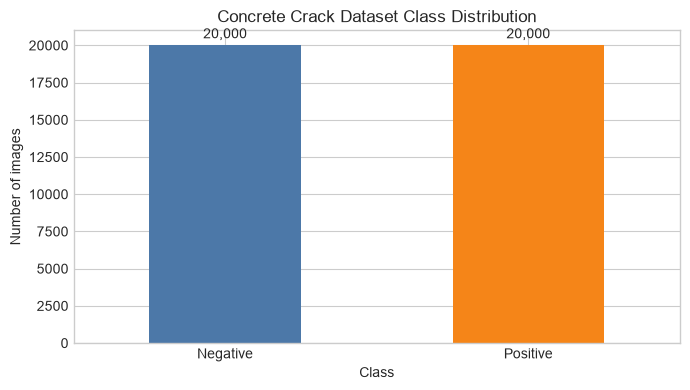

In [12]:
ax = class_counts.plot(kind="bar", color=["#4C78A8", "#F58518"], figsize=(7, 4))
ax.set_title("Concrete Crack Dataset Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=0)
for bar in ax.patches:
    ax.annotate(f"{int(bar.get_height()):,}", (bar.get_x() + bar.get_width() / 2, bar.get_height()), ha="center", va="bottom", xytext=(0, 3), textcoords="offset points")
plt.tight_layout()
plt.show()


## 6. Display 10 sample images with their labels

Five deterministic samples from each class are displayed. A fixed seed makes the same examples appear on repeated runs.

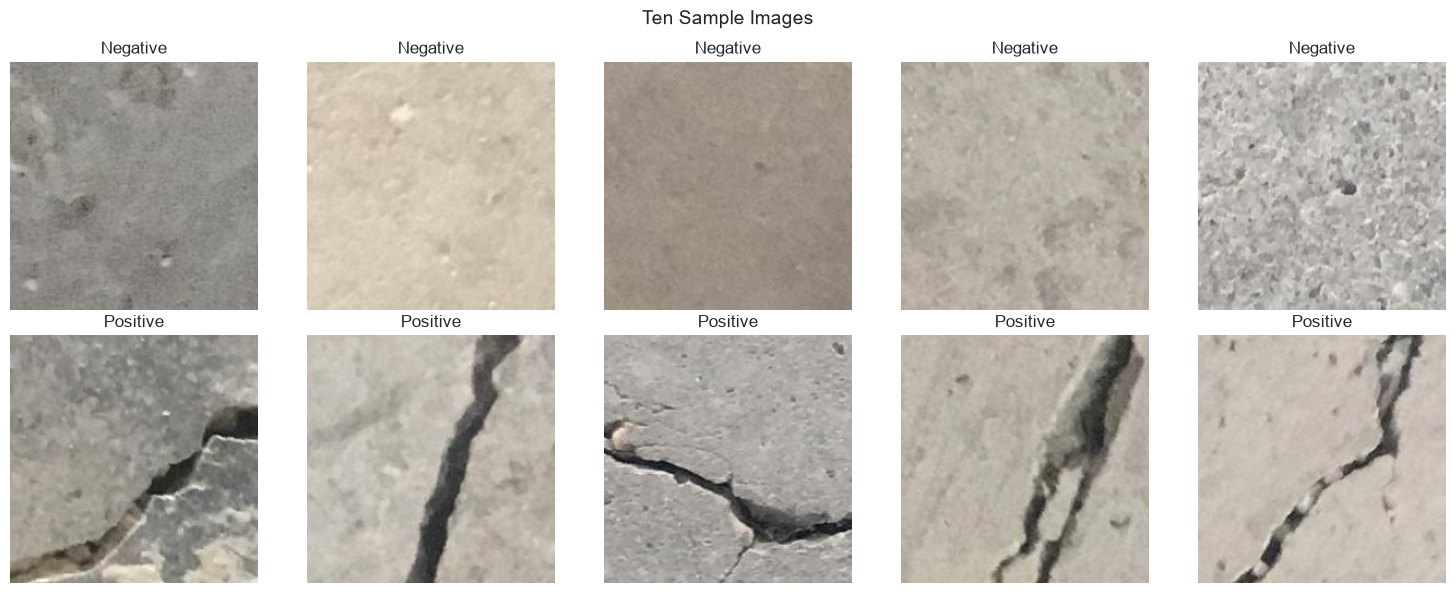

In [13]:
rng = np.random.default_rng(42)
sample_paths = []
for name in class_names:
    paths = image_paths[name]
    count = min(5, len(paths))
    indices = rng.choice(len(paths), size=count, replace=False)
    sample_paths.extend((paths[index], name) for index in sorted(indices))

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.ravel()
for axis, (image_path, name) in zip(axes, sample_paths):
    with Image.open(image_path) as image:
        axis.imshow(image)
    axis.set_title(name)
    axis.axis("off")
for axis in axes[len(sample_paths):]:
    axis.axis("off")
fig.suptitle("Ten Sample Images", fontsize=14)
plt.tight_layout()
plt.show()


## 7. Check image dimensions, formats, and color modes

Dimensions are the width and height in pixels. The format is the file encoding detected by Pillow, and the mode describes the pixel representation, such as RGB or grayscale (`L`).

In [14]:
image_properties = []
property_errors = []
for name in class_names:
    for image_path in image_paths[name]:
        try:
            with Image.open(image_path) as image:
                image_properties.append({"class": name, "file": str(image_path), "width": image.width, "height": image.height, "dimensions": f"{image.width} x {image.height}", "format": image.format, "mode": image.mode})
        except (OSError, ValueError) as error:
            property_errors.append({"file": str(image_path), "error": str(error)})

image_properties_df = pd.DataFrame(image_properties)
if image_properties_df.empty:
    raise RuntimeError("No readable image properties were collected.")
print("Most common dimensions:")
display(image_properties_df["dimensions"].value_counts().head(10).to_frame("count"))
print("\nImage formats:")
display(image_properties_df["format"].value_counts().to_frame("count"))
print("\nColor modes:")
display(image_properties_df["mode"].value_counts().to_frame("count"))
if property_errors:
    print(f"Metadata could not be read for {len(property_errors):,} file(s).")


Most common dimensions:


,count
dimensions,
227 x 227,40000



Image formats:


,count
format,
JPEG,40000



Color modes:


,count
mode,
RGB,40000


## 8. Check for corrupted or unreadable images

Pillow's `verify()` checks the file structure. Reopening and loading each image also checks that pixel data can be decoded. Any failures are listed rather than hidden.

In [15]:
corrupted_images = []
for name in class_names:
    for image_path in image_paths[name]:
        try:
            with Image.open(image_path) as image:
                image.load()
        except (OSError, ValueError, SyntaxError) as error:
            corrupted_images.append({"class": name, "file": str(image_path), "error": str(error)})

if corrupted_images:
    corrupted_df = pd.DataFrame(corrupted_images)
    print(f"Found {len(corrupted_df):,} corrupted or unreadable image(s):")
    display(corrupted_df)
else:
    print("No corrupted or unreadable images were found.")


No corrupted or unreadable images were found.


## 9. Observations and conclusions

This final cell summarizes the measured class balance, common image properties, and readability results. These observations provide a baseline before preprocessing or model training.

In [16]:
total_images = int(class_counts.sum())
class_difference = abs(int(class_counts.iloc[0]) - int(class_counts.iloc[1]))
balance_ratio = class_counts.min() / class_counts.max() if class_counts.max() else 0
most_common_dimensions = image_properties_df["dimensions"].mode().iat[0]
most_common_format = image_properties_df["format"].mode().iat[0]
most_common_mode = image_properties_df["mode"].mode().iat[0]

print(f"- The dataset contains {total_images:,} readable image records across two classes.")
print(f"- The class counts differ by {class_difference:,} image(s); the balance ratio is {balance_ratio:.3f}.")
print(f"- The most common image dimensions are {most_common_dimensions} pixels.")
print(f"- The most common format is {most_common_format}, and the most common color mode is {most_common_mode}.")
if corrupted_images or property_errors:
    issue_count = len(corrupted_images) + len(property_errors)
    print(f"- {issue_count:,} image read issue(s) require attention before model training.")
else:
    print("- No unreadable images were detected, so the dataset is ready for the next preprocessing step.")
print("\nConclusion: Apply resizing, normalization, augmentation, and dataset splitting consistently to both classes in later steps.")


- The dataset contains 40,000 readable image records across two classes.
- The class counts differ by 0 image(s); the balance ratio is 1.000.
- The most common image dimensions are 227 x 227 pixels.
- The most common format is JPEG, and the most common color mode is RGB.
- No unreadable images were detected, so the dataset is ready for the next preprocessing step.

Conclusion: Apply resizing, normalization, augmentation, and dataset splitting consistently to both classes in later steps.
